# 02 · Exploratory Data Analysis (EDA)

Sebelum menjalankan algoritma clustering di Notebook 03, kita perlu memahami karakter data 38 provinsi di `data/processed/indikator_digital_provinsi.csv` terlebih dahulu.

Pertanyaan utama yang dijawab notebook ini:
1. **Distribusi:** Seperti apa sebaran tiap indikator dan seberapa lebar jarak antar-provinsi?
2. **Outlier:** Provinsi mana saja yang nilainya ekstrem (sangat tinggi atau sangat rendah)?
3. **Korelasi:** Apakah ada dua indikator yang terlalu mirip (`|r| > 0,9`) sehingga perlu diperhatikan sebelum clustering?
4. **Pola Gap & Paradoks:** Provinsi mana yang unggul di satu lapis (*Akses*), tetapi tertinggal di lapis lain (*Pemanfaatan* / *Keterampilan*)?

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import FEATURES, INDICATORS, MASTER_FILE
from src.visualization import save_matplotlib

sns.set_theme(style="whitegrid")
COLORS = ["#2563eb", "#0891b2", "#0d9488", "#059669", "#d97706", "#dc2626"]

df = pd.read_csv(MASTER_FILE)
print(f"Ukuran data: {df.shape[0]} provinsi x {df.shape[1]} kolom")
print("Missing value total:", int(df.isna().sum().sum()))
df.head()

Ukuran data: 38 provinsi x 7 kolom
Missing value total: 0


,provinsi,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls
0,Aceh,70.03,68.21,17.59,89.67,93.72,10.26
1,Sumatera Utara,79.60,70.40,16.32,87.68,96.78,10.13
2,Sumatera Barat,80.47,70.33,22.21,93.55,97.15,10.03
3,Riau,80.99,76.17,18.54,91.44,97.29,9.56
4,Jambi,76.27,71.03,18.39,90.23,97.39,9.18


## 1. Statistik Deskriptif, Kemencengan (Skewness), & Provinsi Ekstrem
Selain rata-rata dan median, kita tampilkan **skewness** (kemencengan distribusi) serta nama provinsi **tertinggi** dan **terendah** di tiap indikator. Jika `skew` bernilai negatif kuat (misal `< -1`), artinya sebagian besar provinsi berkumpul di angka tinggi, tetapi ada beberapa provinsi yang jauh tertinggal di bawah.

In [2]:
stats = df[FEATURES].describe().T[["min", "25%", "50%", "mean", "75%", "max", "std"]]
stats["range"] = stats["max"] - stats["min"]
stats["skew"] = df[FEATURES].skew()
stats["prov_terendah"] = [df.loc[df[c].idxmin(), "provinsi"] for c in FEATURES]
stats["prov_tertinggi"] = [df.loc[df[c].idxmax(), "provinsi"] for c in FEATURES]
stats.round(2)

,min,25%,50%,mean,75%,max,std,range,skew,prov_terendah,prov_tertinggi
pct_internet,15.40,70.40,76.57,73.21,80.77,91.32,14.11,75.92,-2.61,Papua Pegunungan,Kepulauan Riau
pct_hp,22.49,67.90,70.18,68.99,73.57,84.47,11.40,61.98,-2.46,Papua Pegunungan,DKI Jakarta
pct_komputer,1.96,16.81,18.46,19.93,22.91,38.42,6.72,36.46,0.35,Papua Pegunungan,DKI Jakarta
pct_desa_4g,19.53,83.04,90.08,85.45,94.41,100.00,17.45,80.47,-2.91,Papua Pegunungan,DKI Jakarta
pct_skill_tik,15.79,93.91,97.22,90.68,97.99,99.54,17.42,83.75,-3.26,Papua Pegunungan,DI Yogyakarta
rls,4.31,8.62,9.22,9.19,9.99,11.76,1.27,7.45,-1.60,Papua Pegunungan,DKI Jakarta


**Cara membaca tabel di atas:**
- Bandingkan kolom `mean` (rata-rata) dengan `50%` (median). Jika `mean < median` dan `skew` negatif, itu tanda ada provinsi ekstrem rendah yang menarik rata-rata nasional ke bawah.
- Perhatikan kolom `range` (`max - min`): semakin besar selisihnya, semakin timpang ketimpangan antar-provinsi pada indikator tersebut.

## 2. Distribusi Tiap Indikator (Histogram + KDE)
Visualisasi sebaran 38 provinsi untuk masing-masing indikator, dilengkapi garis putus-putus untuk **mean** (merah) dan **median** (hitam).

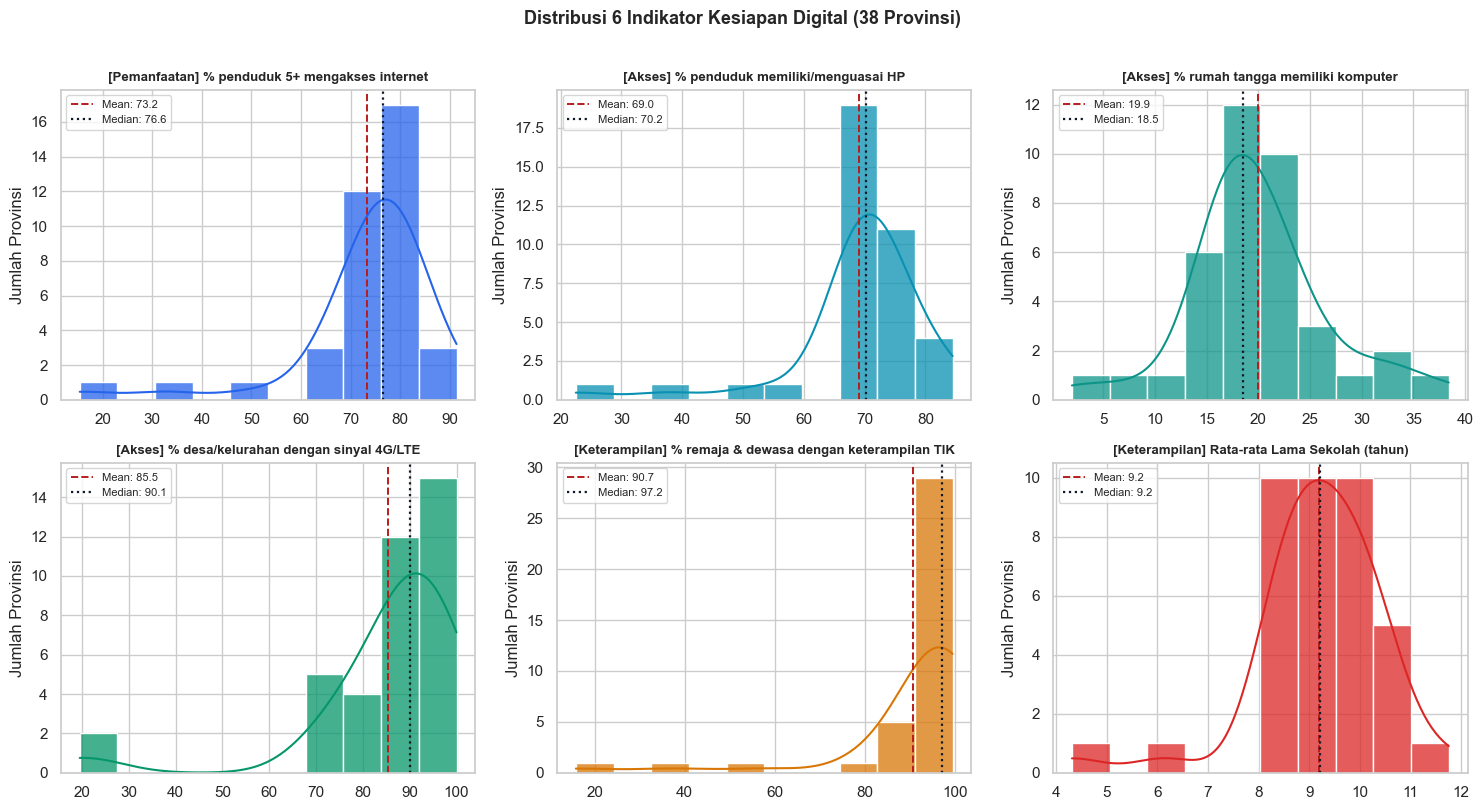

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col, color in zip(axes.flat, FEATURES, COLORS):
    label, lapis = INDICATORS[col]
    sns.histplot(df[col], kde=True, bins=10, color=color, edgecolor="white", alpha=0.75, ax=ax)
    ax.axvline(df[col].mean(), color="#b91c1c", linestyle="--", linewidth=1.4, label=f"Mean: {df[col].mean():.1f}")
    ax.axvline(df[col].median(), color="#111827", linestyle=":", linewidth=1.6, label=f"Median: {df[col].median():.1f}")
    ax.set_title(f"[{lapis}] {label}", fontsize=9.5, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel("Jumlah Provinsi")
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Distribusi 6 Indikator Kesiapan Digital (38 Provinsi)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
save_matplotlib(fig, "02_distribusi")
plt.show()

**Hal yang perlu dicermati dari histogram:**
- Indikator mana yang bentuknya menceng kiri (*left-skewed*, ekor panjang ke angka kecil)?
- Indikator mana yang lebih menyebar merata seperti `pct_komputer` dan `rls`? Fitur yang menyebar merata biasanya sangat membantu membedakan provinsi kelas menengah dan atas saat clustering.

## 3. Deteksi Outlier (Boxplot & Aturan IQR)
Algoritma **K-Means** menggunakan rata-rata jarak (centroid), sehingga sensitif terhadap outlier ekstrem. Di sini kita mendeteksi outlier secara formal dengan metode **IQR** (`< Q1 - 1.5*IQR` atau `> Q3 + 1.5*IQR`) sekaligus menandai nama provinsinya langsung di grafik.

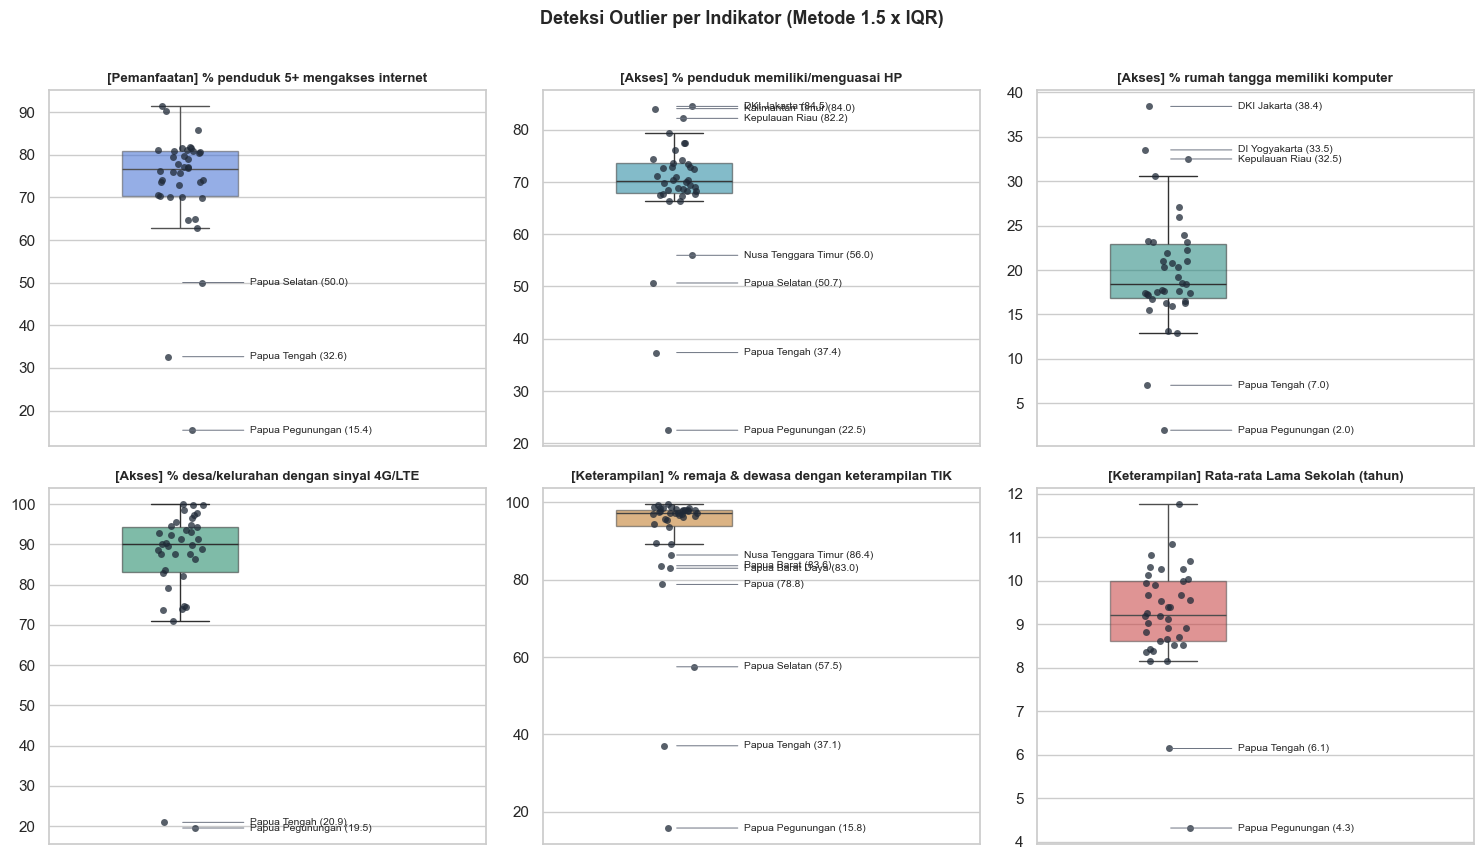

Total temuan outlier: 26 sel across 11 provinsi


,indikator,provinsi,nilai,tipe_outlier
0,pct_internet,Papua Pegunungan,15.40,Rendah
1,pct_internet,Papua Tengah,32.64,Rendah
2,pct_internet,Papua Selatan,50.02,Rendah
3,pct_hp,Papua Pegunungan,22.49,Rendah
4,pct_hp,Papua Tengah,37.35,Rendah
5,pct_hp,Papua Selatan,50.67,Rendah
6,pct_hp,Nusa Tenggara Timur,55.97,Rendah
7,pct_hp,Kepulauan Riau,82.18,Tinggi
8,pct_hp,Kalimantan Timur,84.04,Tinggi
9,pct_hp,DKI Jakarta,84.47,Tinggi


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
outlier_records = []

for ax, col, color in zip(axes.flat, FEATURES, COLORS):
    label, lapis = INDICATORS[col]
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

    sns.boxplot(y=df[col], ax=ax, color=color, width=0.4, boxprops={"alpha": 0.55}, fliersize=0)
    sns.stripplot(y=df[col], ax=ax, color="#1f2937", size=5, alpha=0.75, jitter=0.08)

    outliers = df[(df[col] < low) | (df[col] > high)].sort_values(col)
    for _, row in outliers.iterrows():
        tipe = "Tinggi" if row[col] > high else "Rendah"
        outlier_records.append({
            "indikator": col,
            "provinsi": row["provinsi"],
            "nilai": row[col],
            "tipe_outlier": tipe,
        })
        ax.annotate(
            f"{row['provinsi']} ({row[col]:.1f})",
            xy=(0, row[col]),
            xytext=(0.24, row[col]),
            fontsize=7.5,
            va="center",
            arrowprops={"arrowstyle": "-", "color": "#6b7280", "lw": 0.7},
        )

    ax.set_xlim(-0.45, 1.05)
    ax.set_title(f"[{lapis}] {label}", fontsize=9.5, fontweight="bold")
    ax.set_ylabel("")

fig.suptitle("Deteksi Outlier per Indikator (Metode 1.5 x IQR)", fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
save_matplotlib(fig, "02_boxplot")
plt.show()

outlier_df = pd.DataFrame(outlier_records)
print(f"Total temuan outlier: {len(outlier_df)} sel across {outlier_df['provinsi'].nunique()} provinsi")
outlier_df

**Kenapa outlier di sini TIDAK langsung dihapus?**
- Provinsi seperti Papua Pegunungan, Papua Tengah, atau DKI Jakarta bukan kesalahan input data (*data error*), melainkan **fakta ketimpangan nyata** yang justru menjadi fokus utama project ini.
- Sebagai gantinya, di Notebook 03 nanti kita akan **mempertahankan seluruh 38 provinsi** dan menguji ketahanan hasil K-Means dengan pembanding **Hierarchical Ward** (serta opsional **K-Medoids** yang lebih tahan outlier).

## 4. Korelasi Antar Indikator (Pearson vs Spearman)
Kita membandingkan dua ukuran korelasi:
- **Pearson (`r`)**: mengukur hubungan linear, sensitif terhadap outlier ekstrem.
- **Spearman (`rho`)**: mengukur hubungan berbasis *peringkat*, jauh lebih tahan terhadap outlier ekstrem.

Perbandingan ini penting: jika Pearson > 0,9 tetapi Spearman jauh lebih rendah, artinya tingginya Pearson ikut didorong oleh 2–3 provinsi outlier ekstrem, bukan karena kedua indikator identik di seluruh Indonesia.

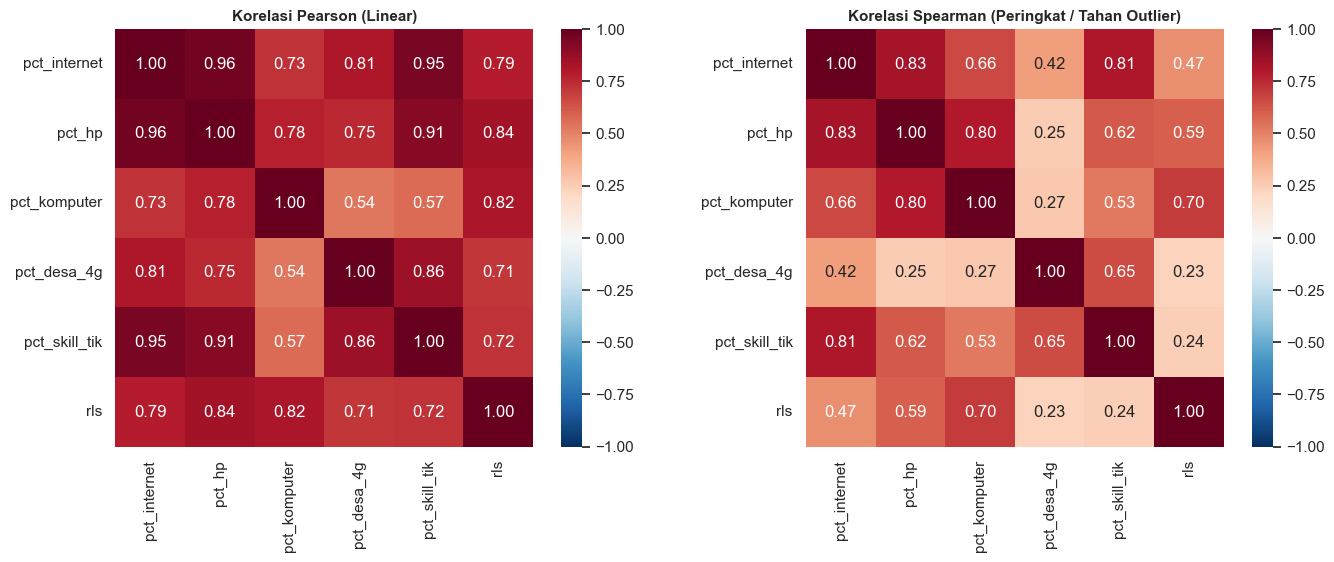

,fitur_1,fitur_2,pearson,spearman
0,pct_internet,pct_hp,0.964,0.833
1,pct_internet,pct_skill_tik,0.953,0.811
2,pct_hp,pct_skill_tik,0.907,0.617
3,pct_desa_4g,pct_skill_tik,0.859,0.649


In [5]:
corr_pearson = df[FEATURES].corr(method="pearson")
corr_spearman = df[FEATURES].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Korelasi Pearson (Linear)", fontsize=11, fontweight="bold")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=axes[1])
axes[1].set_title("Korelasi Spearman (Peringkat / Tahan Outlier)", fontsize=11, fontweight="bold")

plt.tight_layout()
save_matplotlib(fig, "02_korelasi")
plt.show()

# Cetak pasangan fitur dengan |Pearson| > 0.85
high_corr = []
for i, c1 in enumerate(FEATURES):
    for c2 in FEATURES[i + 1:]:
        r_p = corr_pearson.loc[c1, c2]
        r_s = corr_spearman.loc[c1, c2]
        if abs(r_p) > 0.85:
            high_corr.append({"fitur_1": c1, "fitur_2": c2, "pearson": round(r_p, 3), "spearman": round(r_s, 3)})

pd.DataFrame(high_corr) if high_corr else "Tidak ada pasangan dengan |Pearson| > 0.85"

**Cara mengambil keputusan dari heatmap korelasi:**
- Jika ada pasangan dengan `|Pearson| > 0.90`, bandingkan juga nilai `Spearman`-nya.
- Apabila nilai `Spearman` jauh lebih moderat, itu membuktikan kedua indikator masih membawa informasi peringkat yang berbeda antar-provinsi (contoh: provinsi dengan kepemilikan HP serupa bisa memiliki pemanfaatan internet atau skill TIK berbeda), sehingga tetap layak dipertimbangkan di clustering — atau kita bisa menguji perbandingan hasil clustering dengan semua 6 fitur vs setelah reduksi fitur di Notebook 03.

## 5. Eksplorasi Hubungan Antar Lapis (*Akses ≠ Pemanfaatan ≠ Keterampilan*)
Dua scatterplot ini menguji langsung sudut cerita utama project kita:
1. **Kiri (`pct_hp` vs `pct_internet`):** Apakah provinsi dengan kepemilikan HP tinggi otomatis tinggi juga pengguna internetnya?
2. **Kanan (`pct_desa_4g` vs `pct_skill_tik`):** Apakah sinyal 4G yang merata otomatis diikuti keterampilan TIK yang tinggi?

Garis putus-putus menandai **median nasional** (membagi grafik menjadi 4 kuadran). Provinsi di kuadran **kanan-bawah** (akses di atas median, tetapi pemanfaatan/skill di bawah median) adalah kandidat **paradoks**.

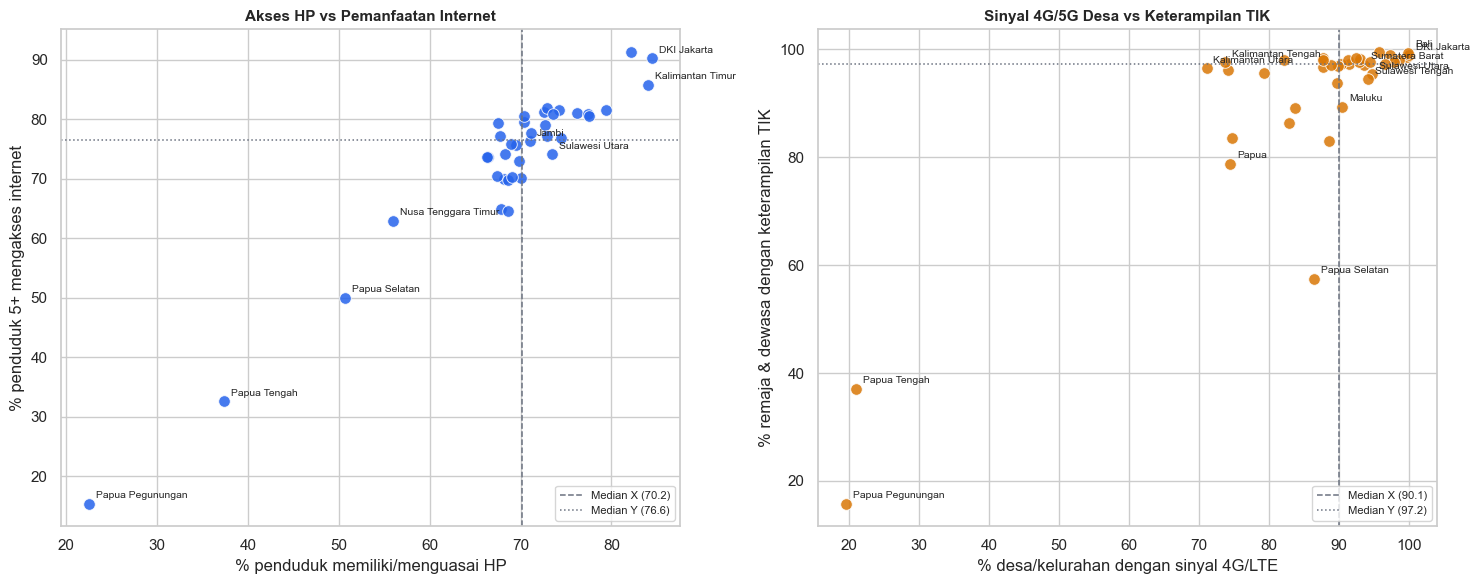

In [6]:
pairs = [
    ("pct_hp", "pct_internet", "Akses HP vs Pemanfaatan Internet", "#2563eb"),
    ("pct_desa_4g", "pct_skill_tik", "Sinyal 4G/5G Desa vs Keterampilan TIK", "#d97706"),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (x_col, y_col, title, color) in zip(axes, pairs):
    x_med, y_med = df[x_col].median(), df[y_col].median()
    sns.scatterplot(data=df, x=x_col, y=y_col, color=color, s=70, alpha=0.85, edgecolor="white", ax=ax)
    ax.axvline(x_med, color="#6b7280", linestyle="--", linewidth=1.1, label=f"Median X ({x_med:.1f})")
    ax.axhline(y_med, color="#6b7280", linestyle=":", linewidth=1.1, label=f"Median Y ({y_med:.1f})")

    # Beri label pada provinsi ekstrem (tertinggi/terendah) & kandidat kuadran paradoks
    highlight = (
        (df[x_col] >= df[x_col].nlargest(2).min())
        | (df[y_col] <= df[y_col].nsmallest(4).max())
        | ((df[x_col] > x_med) & (df[y_col] < y_med))
        | (df[x_col] <= df[x_col].nsmallest(4).max())
    )
    for _, row in df[highlight].iterrows():
        ax.annotate(
            row["provinsi"],
            xy=(row[x_col], row[y_col]),
            xytext=(5, 4),
            textcoords="offset points",
            fontsize=7.5,
        )

    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_xlabel(INDICATORS[x_col][0])
    ax.set_ylabel(INDICATORS[y_col][0])
    ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
save_matplotlib(fig, "02_scatter_lapis")
plt.show()

**Cara membaca grafik kuadran di atas:**
- **Kanan-atas:** Tinggi di kedua indikator (kandidat pusat digital).
- **Kiri-bawah:** Rendah di kedua indikator (terhambat sejak lapis akses/infrastruktur).
- **Kanan-bawah (Paradoks):** Akses/sinyal sudah di atas median nasional, tetapi pemanfaatan atau keterampilan masih di bawah median — ini bukti awal bahwa membangun infrastruktur saja tidak cukup.

## 6. Peringkat Provinsi & Ketimpangan Antar-Indikator
Kita ubah nilai tiap indikator menjadi peringkat (`1` = tertinggi, `38` = terendah) untuk melihat:
1. Provinsi dengan rata-rata peringkat terbaik dan terbawah.
2. Provinsi dengan **gap peringkat terbesar** (`max_rank - min_rank`) — yaitu daerah yang sangat unggul di satu indikator, tetapi jauh tertinggal di indikator lain.

In [7]:
ranks = df.set_index("provinsi")[FEATURES].rank(ascending=False)
ranks["rata_rank"] = ranks[FEATURES].mean(axis=1)
ranks["gap_rank"] = ranks[FEATURES].max(axis=1) - ranks[FEATURES].min(axis=1)

print("=== 10 Provinsi Peringkat Rata-rata Tertinggi ===")
display(ranks.sort_values("rata_rank").head(10).round(1))

print("=== 10 Provinsi Peringkat Rata-rata Terendah ===")
display(ranks.sort_values("rata_rank", ascending=False).head(10).round(1))

print("=== 10 Provinsi dengan Ketimpangan Peringkat Antar-Indikator Terbesar ===")
display(ranks.sort_values("gap_rank", ascending=False).head(10).round(1))

=== 10 Provinsi Peringkat Rata-rata Tertinggi ===


,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls,rata_rank,gap_rank
provinsi,,,,,,,,
DKI Jakarta,2.0,1.0,1.0,1.0,4.0,1.0,1.7,3.0
DI Yogyakarta,4.0,13.0,2.0,8.0,1.0,4.0,5.3,12.0
Bali,9.0,6.0,5.0,2.0,2.0,11.0,5.8,9.0
Kepulauan Riau,1.0,3.0,3.0,26.0,7.0,2.0,7.0,25.0
Kalimantan Timur,3.0,2.0,4.0,30.0,10.0,5.0,9.0,28.0
Kepulauan Bangka Belitung,6.0,9.0,13.0,3.0,5.0,26.0,10.3,23.0
Banten,10.0,10.0,8.0,13.0,8.0,14.0,10.5,6.0
Jawa Barat,7.0,15.0,14.0,4.0,11.0,19.0,11.7,15.0
Sulawesi Selatan,18.0,12.0,9.0,10.0,13.0,20.0,13.7,11.0


=== 10 Provinsi Peringkat Rata-rata Terendah ===


,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls,rata_rank,gap_rank
provinsi,,,,,,,,
Papua Pegunungan,38.0,38.0,38.0,38.0,38.0,38.0,38.0,0.0
Papua Tengah,37.0,37.0,37.0,37.0,37.0,37.0,37.0,0.0
Nusa Tenggara Timur,35.0,35.0,34.0,29.0,32.0,34.0,33.2,6.0
Papua Selatan,36.0,36.0,27.0,27.0,36.0,28.0,31.7,9.0
Papua Barat,30.0,20.0,30.0,32.0,33.0,33.0,29.7,13.0
Sulawesi Barat,25.0,34.0,33.0,31.0,26.0,29.0,29.7,9.0
Kalimantan Barat,21.0,24.0,28.0,34.0,25.0,35.5,27.9,14.5
Maluku Utara,33.0,29.0,24.0,28.0,31.0,13.0,26.3,20.0
Nusa Tenggara Barat,26.0,33.0,36.0,7.0,18.0,30.5,25.1,29.0


=== 10 Provinsi dengan Ketimpangan Peringkat Antar-Indikator Terbesar ===


,pct_internet,pct_hp,pct_komputer,pct_desa_4g,pct_skill_tik,rls,rata_rank,gap_rank
provinsi,,,,,,,,
Jawa Tengah,17.0,30.0,29.0,6.0,3.0,35.5,20.1,32.5
Kalimantan Utara,5.0,4.0,6.0,36.0,24.0,16.0,15.2,32.0
Kalimantan Tengah,11.0,5.0,16.0,35.0,16.0,22.0,17.5,30.0
Nusa Tenggara Barat,26.0,33.0,36.0,7.0,18.0,30.5,25.1,29.0
Papua,34.0,26.0,10.0,33.0,35.0,6.0,24.0,29.0
Maluku,32.0,25.0,17.0,18.0,30.0,3.0,20.8,29.0
Kalimantan Timur,3.0,2.0,4.0,30.0,10.0,5.0,9.0,28.0
Jawa Timur,24.0,27.0,26.0,5.0,15.0,32.0,21.5,27.0
Papua Barat Daya,29.0,23.0,7.0,23.0,34.0,23.0,23.2,27.0


## 7. Ringkasan & Catatan EDA

### Q&A
- **Apakah data 38 provinsi sudah siap masuk tahap clustering?** Ya, seluruh 38 provinsi lengkap tanpa *missing value*, tetapi memiliki skala satuan berbeda (persentase vs tahun RLS) dan outlier ekstrem — sehingga **wajib distandardisasi (z-score)** dan diuji ketahanannya di Notebook 03.

### Data Analysis Key Findings
- **Rentang ketimpangan sangat lebar:** Terdapat kesenjangan tajam antara provinsi termaju (seperti DKI Jakarta dan Kepulauan Riau) dengan provinsi paling tertinggal (khususnya Papua Pegunungan dan Papua Tengah).
- **Outlier bersifat substantif (bukan error):** Provinsi outlier bawah dan atas merepresentasikan ketimpangan nyata antarwilayah Indonesia, sehingga dipertahankan dalam pemodelan.
- **Cek hasil korelasi & gap peringkat:** Catat pasangan fitur dengan korelasi tertinggi (Pearson vs Spearman) serta 2–3 provinsi dengan `gap_rank` paling kontras dari output cell di atas.

### Insights or Next Steps
- Lanjut ke **Notebook 03 (`03_clustering_modeling.ipynb`)** untuk melakukan standardisasi z-score, memilih jumlah cluster (`k`) optimal dengan Elbow + Silhouette + Davies-Bouldin, serta membandingkan **K-Means** dengan **Hierarchical Ward**.
- Jika ada pasangan fitur dengan korelasi Pearson sangat tinggi (`> 0.90`), kita dapat membandingkan kestabilan cluster sebelum dan sesudah penyesuaian fitur di Notebook 03.